In [36]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from scipy.special import expit
from scipy.special import softmax
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor

In [37]:
# 데이터 가져오기
picher = pd.read_csv('data/picher_stats_2017.csv')
picher.head(2)

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000


In [38]:
picher.columns

Index(['선수명', '팀명', '승', '패', '세', '홀드', '블론', '경기', '선발', '이닝', '삼진/9',
       '볼넷/9', '홈런/9', 'BABIP', 'LOB%', 'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR',
       '연봉(2018)', '연봉(2017)'],
      dtype='str')

In [39]:
label = picher['연봉(2018)']
team = picher['팀명']
data = picher[picher.columns[2:-2]]
# data = picher[picher.columns.difference(['선수명','팀명','연봉(2018)'])]
data.head(2)

,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,볼넷/9,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR
0,16,7,0,0,0,30,30,190.0,8.95,2.13,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62
1,11,11,1,0,0,30,29,185.1,7.43,1.85,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08


In [40]:
# 원핫인코딩
team = team.to_numpy().reshape(-1,1)
encoder = OneHotEncoder(sparse_output=False,drop='first', dtype=int)

result = encoder.fit_transform(team)
total_data = np.concatenate((data, result), axis=1)
total_data

array([[16.,  7.,  0., ...,  0.,  0.,  0.],
       [11., 11.,  1., ...,  0.,  0.,  0.],
       [20.,  6.,  0., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  2.,  0., ...,  1.,  0.,  0.],
       [ 0.,  3.,  0., ...,  0.,  1.,  0.],
       [ 4.,  4.,  0., ...,  0.,  0.,  0.]], shape=(152, 26))

In [41]:
train_data,test_data,train_label,test_label = train_test_split(data,label,test_size=0.2,random_state=42)

In [42]:
# 정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data) 

In [43]:
# 릿지 규제 알고리즘
alpha_list = [0.001,0.01,0.1,1,10,100]

train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료') 

완료


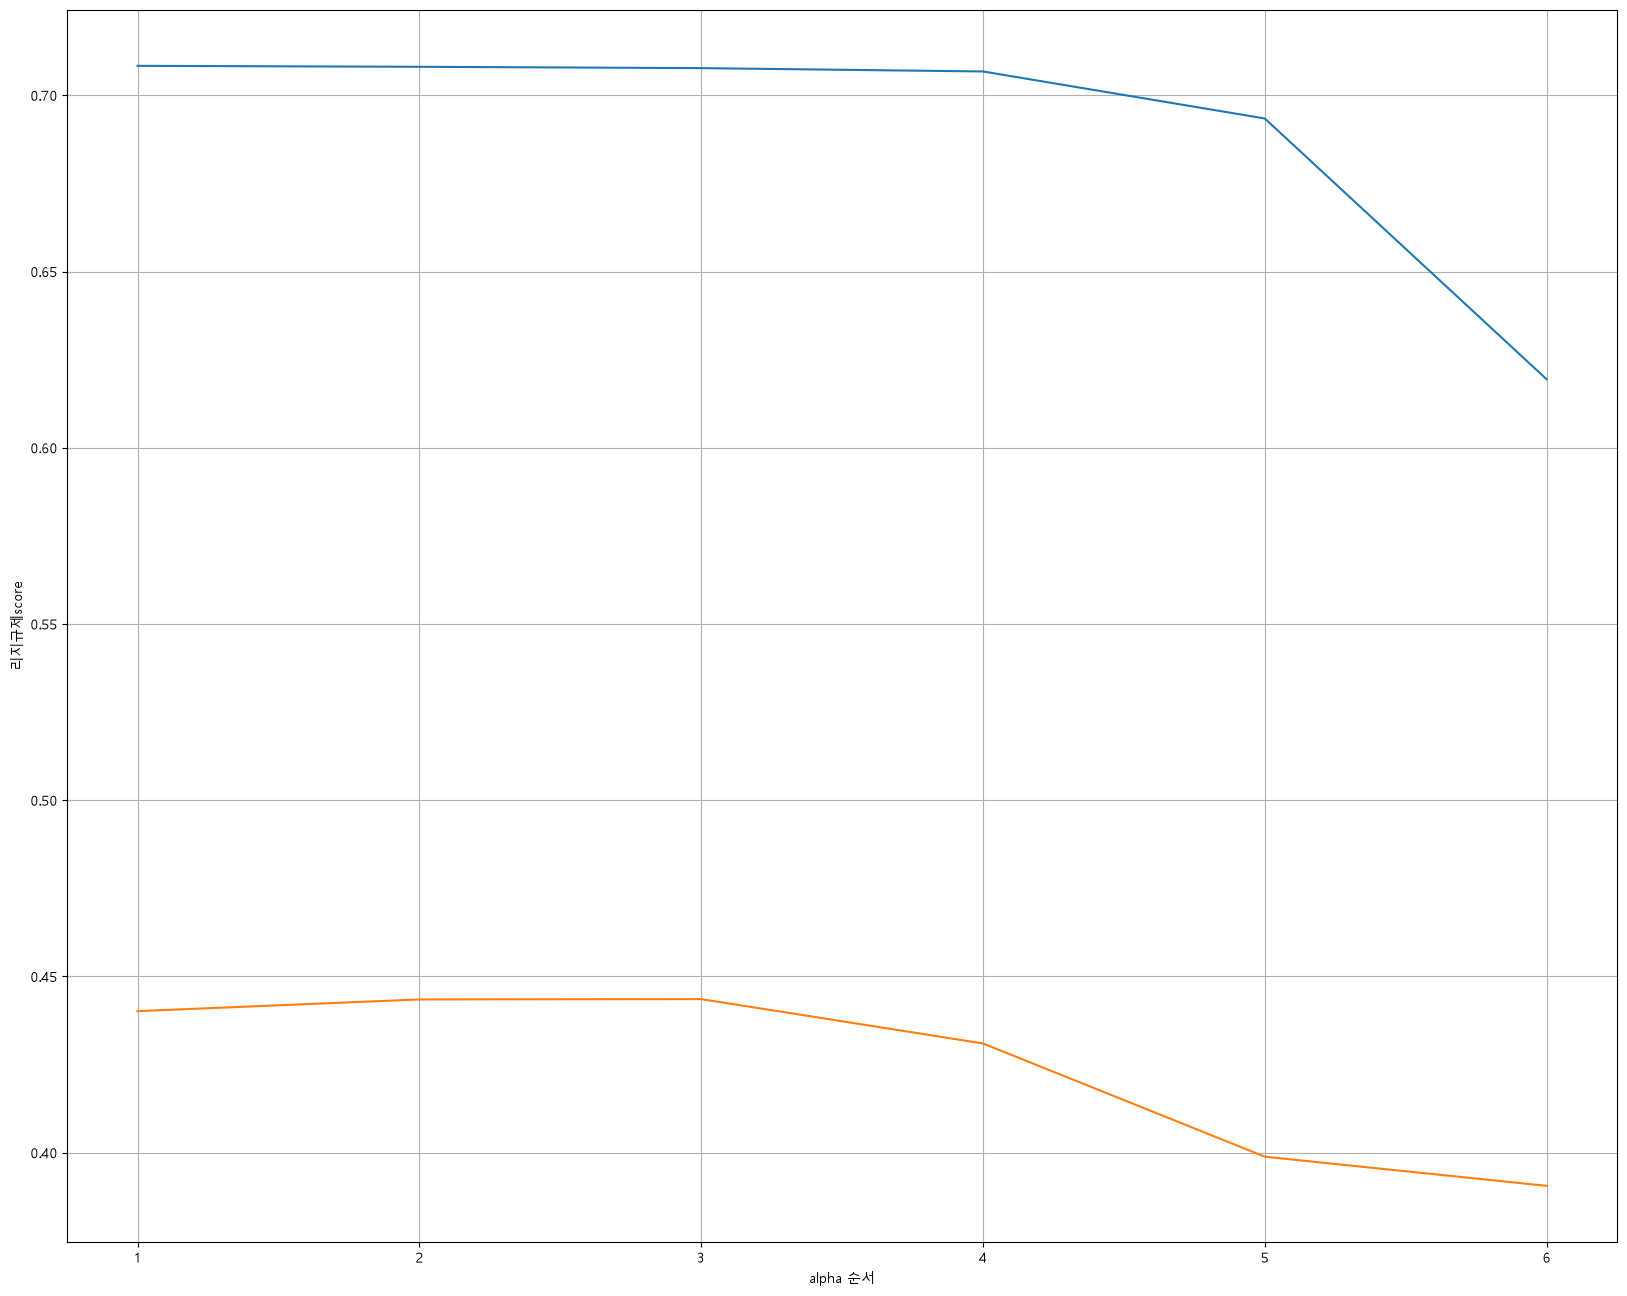

In [44]:
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.grid()
plt.show()

In [59]:
ridge = Ridge(alpha=10)
model = ridge.fit(train_scaled,train_label)
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

train 정확도 :  0.9146248487099662
test 정확도 :  0.8889358101739498


In [46]:
# 회귀분석 통계결과표 : P>|t| 통계량의 절대값보다 크거나 같은 값이 나올 확률
import statsmodels.api as sm

train_scaled = sm.add_constant(train_scaled)
model = sm.OLS(train_label,train_scaled).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.708
Model:                            OLS   Adj. R-squared:                  0.657
Method:                 Least Squares   F-statistic:                     13.76
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           7.63e-20
Time:                        16:44:35   Log-Likelihood:                -1356.9
No. Observations:                 121   AIC:                             2752.
Df Residuals:                     102   BIC:                             2805.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.994e+04   1776.701     11.225      0.000    1.64e+04    2.35e+04
x1          1.394e+04   5418.903      2.572      0.012    3190.752    2.47e+04
x2         -1960.1578   4123.390     -0.475      0.636   -1.01e+04    6218.566
x3          4496.0197   2744.860      1.638      0.105    -948.397    9940.436
x4           190.6735   3121.250      0.061      0.951   -6000.312    6381.659
x5          2794.7248   2777.451      1.006      0.317   -2714.336    8303.786
x6          -1.08e+04   7069.121     -1.527      0.130   -2.48e+04    3226.470
x7         -1.254e+04   1.24e+04     -1.012      0.314   -3.71e+04     1.2e+04
x8          9270.7048   1.54e+04      0.601      0.549   -2.13e+04    3.98e+04
x9          4128.0748   1.29e+04      0.319      0.750   -2.15e+04    2.98e+04
x10         5488.2703   1.25e+04      0.440      0.661   -1.93e+04    3.03e+04
x11         2.032e+04   3.27e+04      0.621      0.536   -4.46e+04    8.53e+04
x12         -914.4960   2944.763     -0.311      0.757   -6755.420    4926.428
x13        -2690.0165   3452.278     -0.779      0.438   -9537.593    4157.560
x14        -2745.2697   5419.507     -0.507      0.614   -1.35e+04    8004.296
x15        -3693.6047   6455.337     -0.572      0.568   -1.65e+04    9110.526
x16        -9.758e+04   1.94e+05     -0.503      0.616   -4.82e+05    2.87e+05
x17         7.982e+04   1.62e+05      0.494      0.623   -2.41e+05    4.01e+05
x18           2.4e+04   5659.784      4.241      0.000    1.28e+04    3.52e+04
==============================================================================
Omnibus:                       38.275   Durbin-Watson:                   1.844
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              201.842
Skew:                           0.894   Prob(JB):                     1.48e-44
Kurtosis:                       9.070   Cond. No.                         366.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

[Text(0, 0, 'const'),
 Text(1, 0, 'x1'),
 Text(2, 0, 'x2'),
 Text(3, 0, 'x3'),
 Text(4, 0, 'x4'),
 Text(5, 0, 'x5'),
 Text(6, 0, 'x6'),
 Text(7, 0, 'x7'),
 Text(8, 0, 'x8'),
 Text(9, 0, 'x9'),
 Text(10, 0, 'x10'),
 Text(11, 0, 'x11'),
 Text(12, 0, 'x12'),
 Text(13, 0, 'x13'),
 Text(14, 0, 'x14'),
 Text(15, 0, 'x15'),
 Text(16, 0, 'x16'),
 Text(17, 0, 'x17'),
 Text(18, 0, 'x18')]

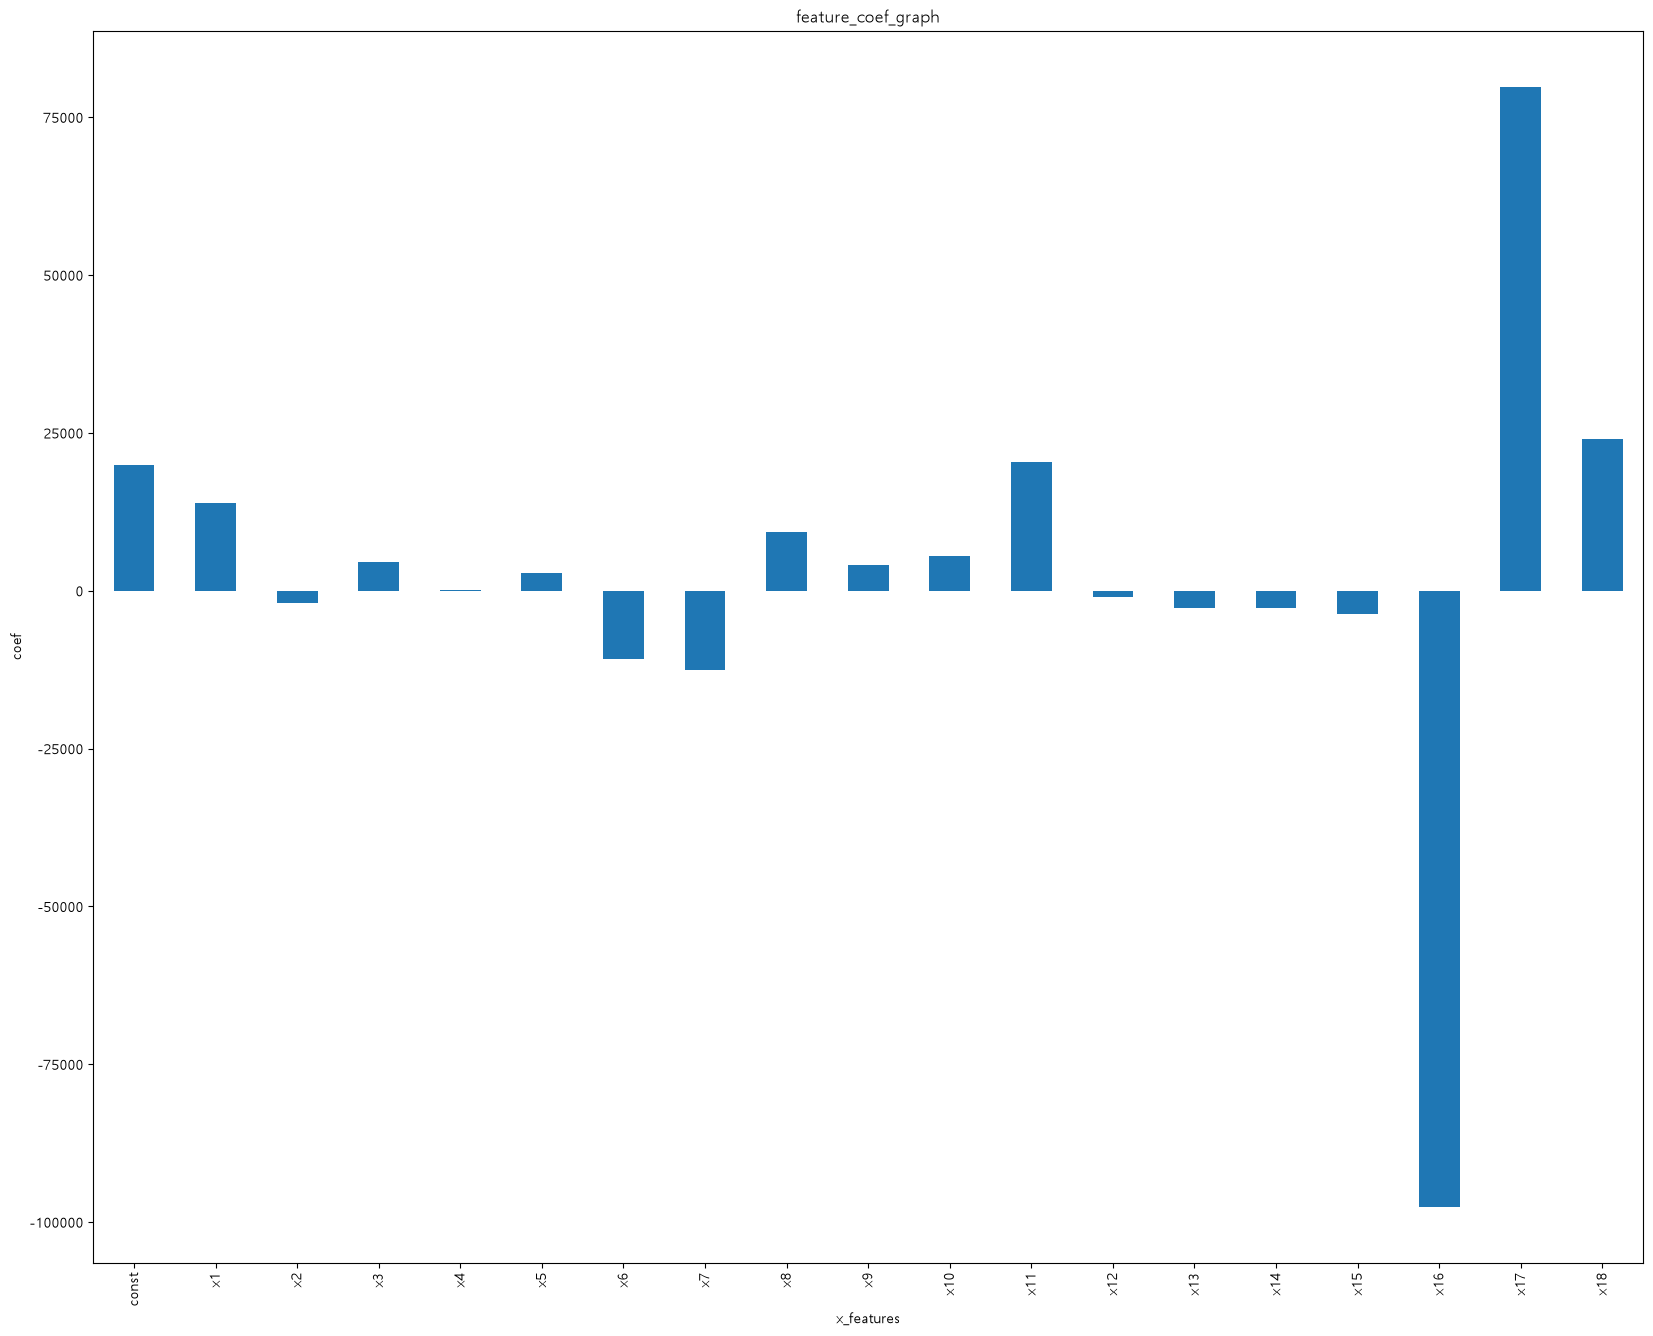

In [47]:
plt.rcParams['figure.figsize'] = [20, 16]

# 회귀 계수를 리스트로 반환
coefs = model.params.tolist()
coefs_series = pd.Series(coefs)

# 변수명을 리스트로 반환
x_labels = model.params.index.tolist()

# 회귀 계수를 출력합니다.
ax = coefs_series.plot(kind='bar')
ax.set_title('feature_coef_graph')
ax.set_xlabel('x_features')
ax.set_ylabel('coef')
ax.set_xticklabels(x_labels)

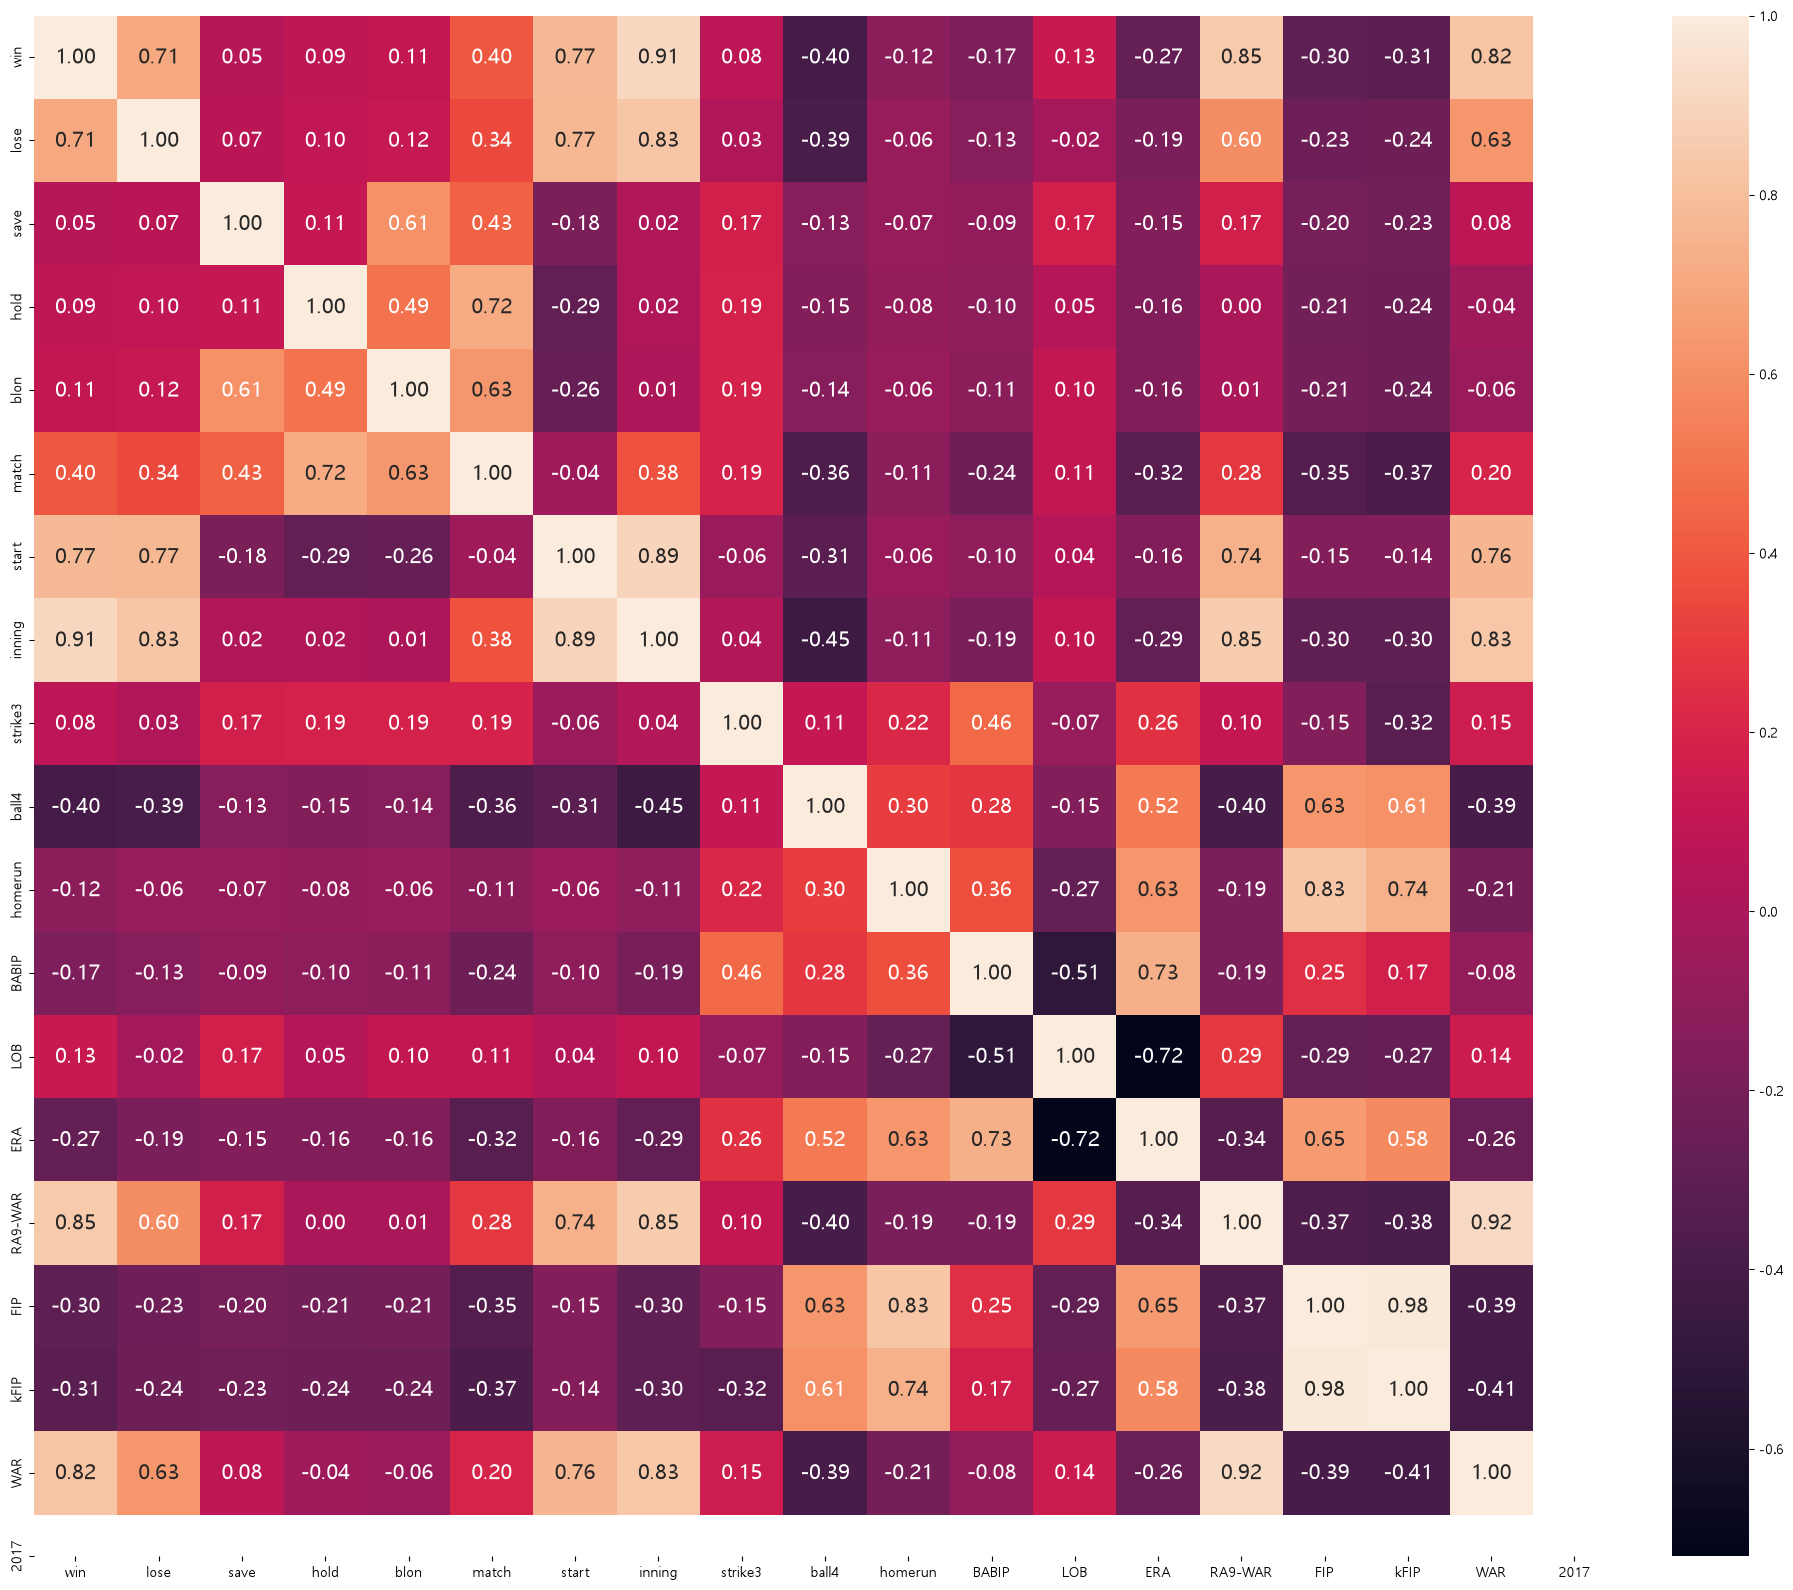

In [48]:
import seaborn as sns

# 피처간의 상관계수 행렬을 계산
corr = picher[data.columns].corr(method='pearson')
show_cols = ['win', 'lose', 'save', 'hold', 'blon', 'match', 'start', 
             'inning', 'strike3', 'ball4', 'homerun', 'BABIP', 'LOB', 
             'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR', '2017']

# corr 행렬 히트맵을 시각화
# plt.rc('font', family='NanumGothicOTF')

hm = sns.heatmap(corr.values,
            cbar=True,
            annot=True, 
            square=True,
            fmt='.2f',
            annot_kws={'size': 15},
            yticklabels=show_cols,
            xticklabels=show_cols)

plt.tight_layout()
plt.show()

In [49]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
# 다중공선성 확인
# 피처마다의 VIF 계수를 출력합니다.
vif = pd.DataFrame()
vif["VIF Factor"] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
vif["features"] = data.columns
vif.round(1) # 소수점 1자리

,VIF Factor,features
0,7.4,승
1,5.2,패
2,2.9,세
3,3.6,홀드
4,2.7,블론
5,13.9,경기
6,36.0,선발
7,59.7,이닝
8,78.6,삼진/9
9,50.7,볼넷/9


In [50]:
# 피처를 재선정합니다.
data = picher[['FIP', 'WAR', '볼넷/9', '삼진/9', '연봉(2017)']]
label = picher['연봉(2018)']

In [51]:
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [52]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data) 

In [53]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 릿지, 라쏘 규제 2가지 형태
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료') 

완료


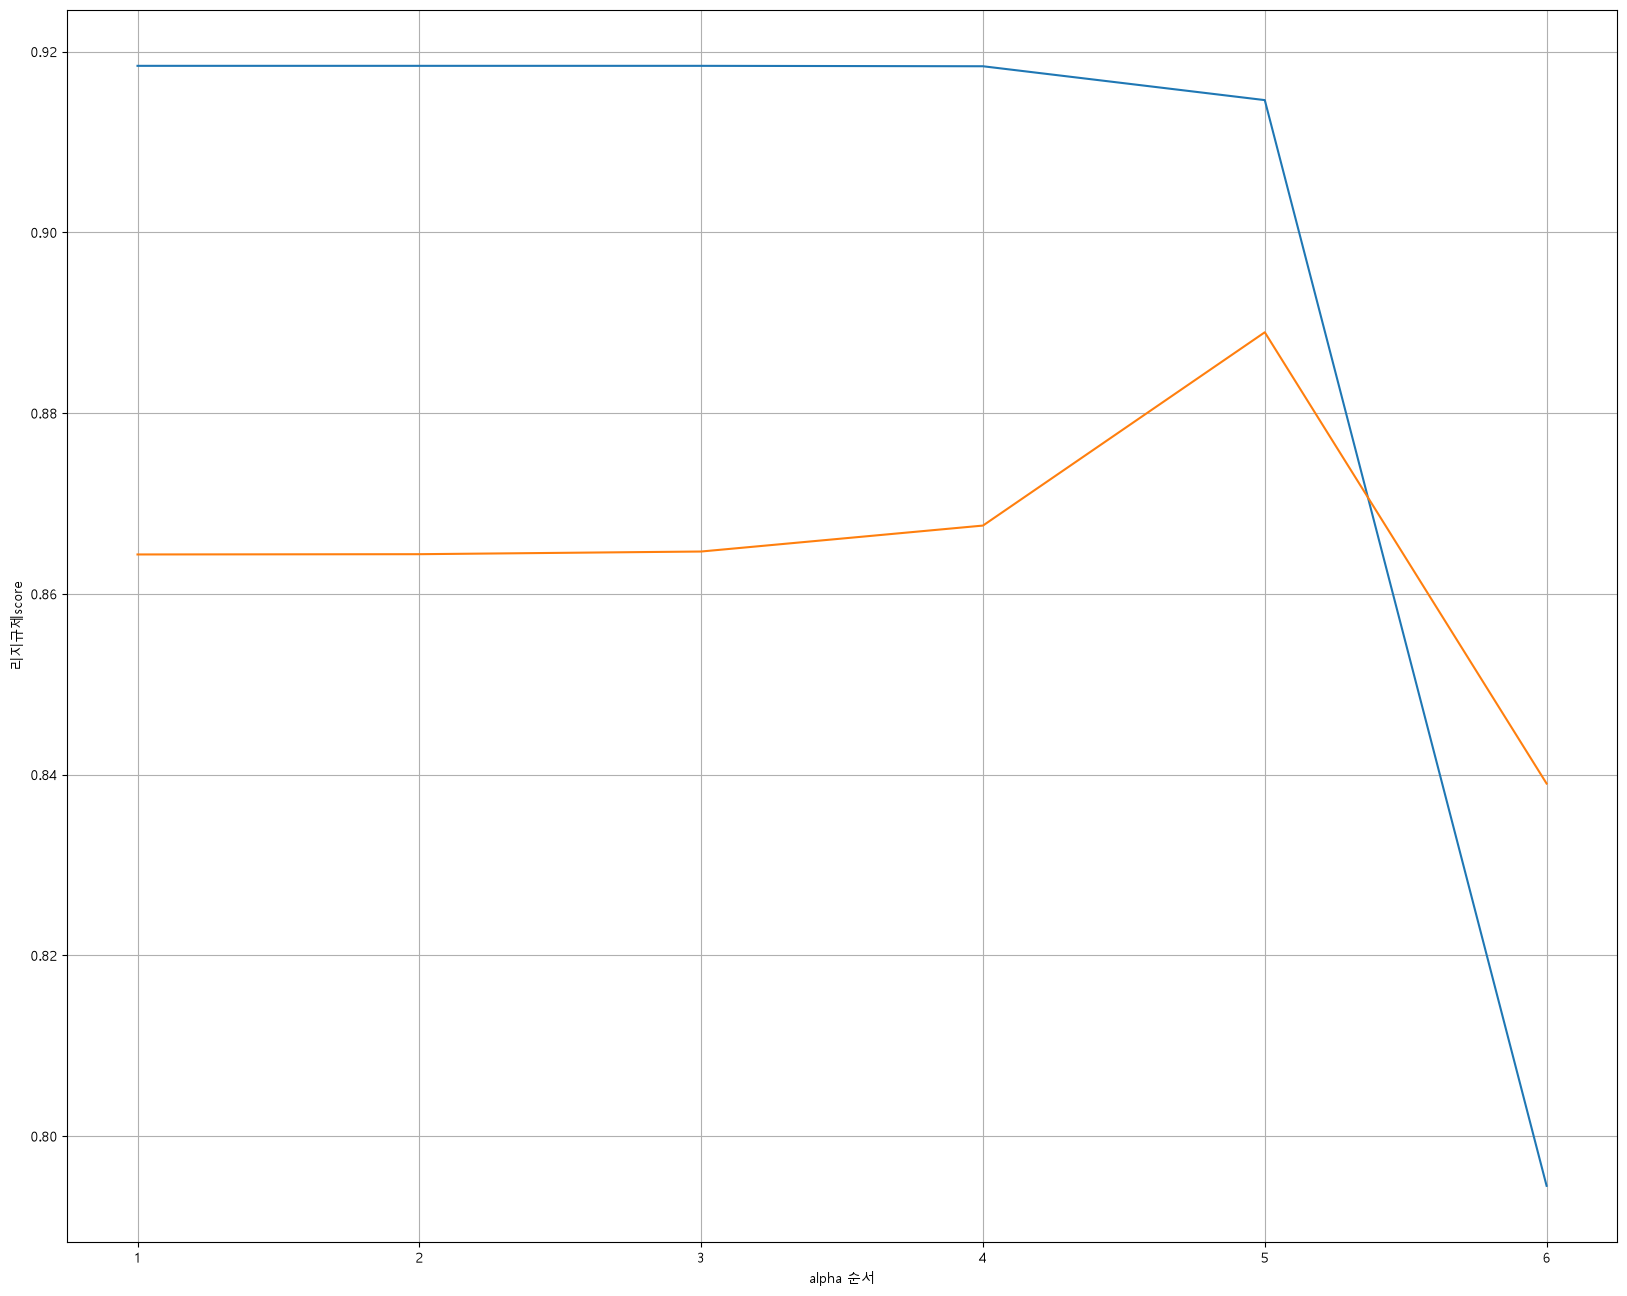

In [54]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
# plt.rc('font', family='Malgun Gothic')
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.grid()
plt.show()

In [55]:
ridge = Ridge(alpha=10)
model = ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

train 정확도 :  0.9146248487099662
test 정확도 :  0.8889358101739498
